# Monte Carlo Pricing and Risk Analysis of Path-Dependent Asian Options

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm

def bs_european_call(S, K, T, r, sigma):
    """Closed-form Black-Scholes price and Greeks for a European Call option."""
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    price = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    delta = norm.cdf(d1)
    gamma = norm.pdf(d1) / (S * sigma * np.sqrt(T))
    vega = S * norm.pdf(d1) * np.sqrt(T) / 100 # per 1% vol 

    return {"price": price, "delta": delta, "gamma": gamma, "vega": vega}

def discrete_geometric_asian_call(S, K, T, r, sigma, M):
    """Exact closed-form price for a discrete geometric-average Asian call option."""
    sigma_g = sigma * np.sqrt((M+1) * (2 * M + 1) / (6 * M**2))
    mu_g = (r - 0.5 * sigma**2) * (M + 1) / (2 * M) + .5 * sigma_g**2

    d1 = (np.log(S / K) + (mu_g + 0.5 * sigma_g**2) * T) / (sigma_g * np.sqrt(T))
    d2 = d1 - sigma_g * np.sqrt(T)

    return np.exp(-r * T) * (S * np.exp(mu_g * T) * norm.cdf(d1) - K * norm.cdf(d2))

# Base parameters
S0, K, T, r, sigma, M = 100., 100., 1., 0.04, 0.20, 252

eu_exact = bs_european_call(S0, K, T, r, sigma)
geo_exact = discrete_geometric_asian_call(S0, K, T, r, sigma, M)

print(f'European Call Exact Price: {eu_exact["price"]:.4f}')
print(f'Geometric Asian Exact Call Price: {geo_exact:.4f}')

European Call Exact Price: 9.9251
Geometric Asian Exact Call Price: 5.3320


The exact geometric Asian payoff $X$ is the control variate for the arithmetic Asian payoff $Y$ with optimal weight $\beta^* = Cov(X,Y)/Var(X)$ cuts the standard error by 95% because $Y$ and $X$ are extremely correlated.

In [2]:
def simulate_gbm_paths(S0, T, r, sigma, M, Z):
    """Vectorized exact GBM path simulation given standard normal shocks Z of shape (N, M)."""
    dt = T / M
    drift = (r - 0.5 * sigma**2) * dt
    diffusion = sigma * np.sqrt(dt) * Z
    log_paths = np.cumsum(drift + diffusion, axis=1)
    return S0 * np.exp(log_paths)

def price_asian_mc(S0, K, T, r, sigma, M, n_paths=50_000, seed=42):
    rng = np.random.default_rng(seed)
    disc = np.exp(-r * T)
    geo_exact = discrete_geometric_asian_call(S0, K, T, r, sigma, M)
    
    # 1. Crude Monte Carlo
    Z = rng.standard_normal((n_paths, M))
    paths = simulate_gbm_paths(S0, T, r, sigma, M, Z)
    arith_payoff = disc * np.maximum(paths.mean(axis=1) - K, 0.0)
    geo_payoff = disc * np.maximum(np.exp(np.log(paths).mean(axis=1)) - K, 0.0)
    
    crude_price = arith_payoff.mean()
    crude_se = arith_payoff.std(ddof=1) / np.sqrt(n_paths)
    
    # 2. Antithetic Variates (same total path budget: N/2 pairs)
    half = n_paths // 2
    Z_half = Z[:half]
    paths_pos = paths[:half]
    paths_neg = simulate_gbm_paths(S0, T, r, sigma, M, -Z_half)
    
    payoff_pos = disc * np.maximum(paths_pos.mean(axis=1) - K, 0.0)
    payoff_neg = disc * np.maximum(paths_neg.mean(axis=1) - K, 0.0)
    anti_pair = 0.5 * (payoff_pos + payoff_neg)
    
    anti_price = anti_pair.mean()
    anti_se = anti_pair.std(ddof=1) / np.sqrt(half)
    
    # 3. Geometric Control Variate
    cov_xy = np.cov(arith_payoff, geo_payoff, ddof=1)[0, 1]
    var_x = np.var(geo_payoff, ddof=1)
    beta_star = cov_xy / var_x
    
    cv_payoff = arith_payoff - beta_star * (geo_payoff - geo_exact)
    cv_price = cv_payoff.mean()
    cv_se = cv_payoff.std(ddof=1) / np.sqrt(n_paths)
    
    # Build summary table
    summary = pd.DataFrame([
        {"Method": "Crude Monte Carlo", "Price ($)": crude_price, "Std Error": crude_se,
         "95% CI Half-Width": 1.96 * crude_se, "VRF (vs Crude)": 1.0, "SE Reduction (%)": 0.0},
        {"Method": "Antithetic Variates", "Price ($)": anti_price, "Std Error": anti_se,
         "95% CI Half-Width": 1.96 * anti_se, "VRF (vs Crude)": (crude_se / anti_se)**2,
         "SE Reduction (%)": (1 - anti_se / crude_se) * 100},
        {"Method": "Geometric Control Variate", "Price ($)": cv_price, "Std Error": cv_se,
         "95% CI Half-Width": 1.96 * cv_se, "VRF (vs Crude)": (crude_se / cv_se)**2,
         "SE Reduction (%)": (1 - cv_se / crude_se) * 100},
    ])
    return summary, beta_star

df_vr, beta = price_asian_mc(S0, K, T, r, sigma, M, n_paths=50_000)
print(f"Optimal Control Variate Beta*: {beta:.4f}")
print(f"Asian vs European Discount:    {(1 - df_vr.loc[2, 'Price ($)'] / eu_exact['price'])*100:.2f}%\n")
print(df_vr.to_string(index=False, float_format=lambda x: f"{x:.5f}"))

Optimal Control Variate Beta*: 1.0352
Asian vs European Discount:    44.19%

                   Method  Price ($)  Std Error  95% CI Half-Width  VRF (vs Crude)  SE Reduction (%)
        Crude Monte Carlo    5.53102    0.03519            0.06897         1.00000           0.00000
      Antithetic Variates    5.57138    0.02522            0.04943         1.94715          28.33605
Geometric Control Variate    5.53924    0.00097            0.00191      1310.32268          97.23745


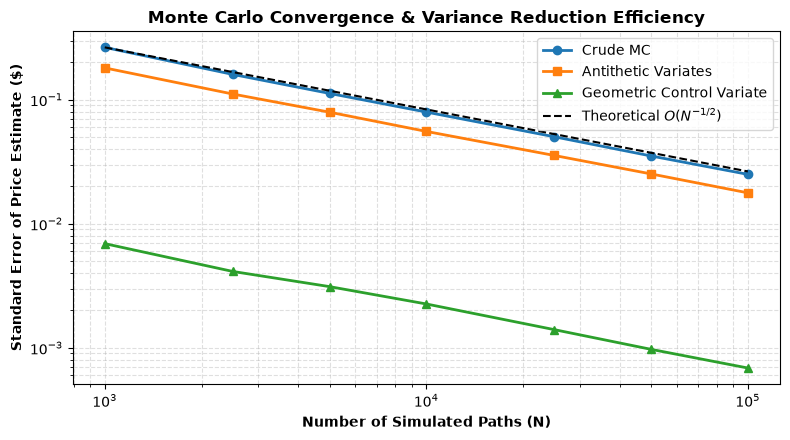

In [3]:
path_counts = [1000, 2500, 5000, 10000, 25000, 50000, 100000]
se_crude, se_anti, se_cv = [], [], []

for n in path_counts:
    res, _ = price_asian_mc(S0, K, T, r, sigma, M, n_paths=n, seed=42)
    se_crude.append(res.loc[0, "Std Error"])
    se_anti.append(res.loc[1, "Std Error"])
    se_cv.append(res.loc[2, "Std Error"])

plt.figure(figsize=(8, 4.5))
plt.loglog(path_counts, se_crude, 'o-', label='Crude MC', linewidth=2)
plt.loglog(path_counts, se_anti, 's-', label='Antithetic Variates', linewidth=2)
plt.loglog(path_counts, se_cv, '^-', label='Geometric Control Variate', linewidth=2)

ref = se_crude[0] * np.sqrt(path_counts[0] / np.array(path_counts))
plt.loglog(path_counts, ref, 'k--', label='Theoretical $O(N^{-1/2})$')

plt.xlabel("Number of Simulated Paths (N)", fontweight='bold')
plt.ylabel("Standard Error of Price Estimate ($)", fontweight='bold')
plt.title("Monte Carlo Convergence & Variance Reduction Efficiency", fontweight='bold')
plt.grid(True, which='both', linestyle='--', alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()


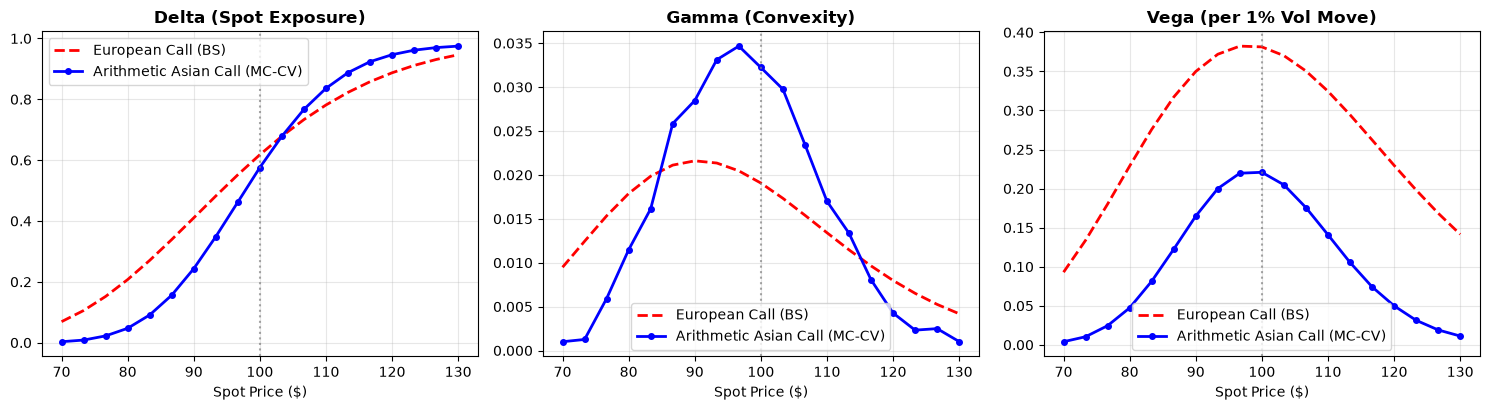

In [4]:
def asian_cv_price_fixed_Z(S, K, T, r, sigma, M, Z):
    """Prices Arithmetic Asian Call with Geometric Control Variate using pre-drawn shocks Z."""
    disc = np.exp(-r * T)
    paths = simulate_gbm_paths(S, T, r, sigma, M, Z)
    arith = disc * np.maximum(paths.mean(axis=1) - K, 0.0)
    geo = disc * np.maximum(np.exp(np.log(paths).mean(axis=1)) - K, 0.0)
    geo_exact = discrete_geometric_asian_call(S, K, T, r, sigma, M)
    
    var_x = np.var(geo, ddof=1)
    beta = np.cov(arith, geo, ddof=1)[0, 1] / var_x if var_x > 1e-12 else 1.0
    return np.mean(arith - beta * (geo - geo_exact))

def asian_greeks_crn(S, K, T, r, sigma, M, Z, dS=0.5, dSigma=0.005):
    """Central finite-difference Greeks using Common Random Numbers."""
    p0 = asian_cv_price_fixed_Z(S, K, T, r, sigma, M, Z)
    p_up = asian_cv_price_fixed_Z(S + dS, K, T, r, sigma, M, Z)
    p_dn = asian_cv_price_fixed_Z(S - dS, K, T, r, sigma, M, Z)
    
    v_up = asian_cv_price_fixed_Z(S, K, T, r, sigma + dSigma, M, Z)
    v_dn = asian_cv_price_fixed_Z(S, K, T, r, sigma - dSigma, M, Z)
    
    return {
        "price": p0,
        "delta": (p_up - p_dn) / (2 * dS),
        "gamma": (p_up - 2 * p0 + p_dn) / (dS**2),
        "vega": (v_up - v_dn) / (2 * dSigma) / 100.0,  # per 1% vol move
    }

# Compare Asian vs European across Spot Prices
rng = np.random.default_rng(123)
Z_greeks = rng.standard_normal((25_000, M))
spots = np.linspace(70, 130, 19)

eu_list = [bs_european_call(s, K, T, r, sigma) for s in spots]
as_list = [asian_greeks_crn(s, K, T, r, sigma, M, Z_greeks) for s in spots]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, greek, title in zip(
    axes,
    ["delta", "gamma", "vega"],
    ["Delta (Spot Exposure)", "Gamma (Convexity)", "Vega (per 1% Vol Move)"]
):
    ax.plot(spots, [d[greek] for d in eu_list], 'r--', lw=2, label='European Call (BS)')
    ax.plot(spots, [d[greek] for d in as_list], 'b-o', ms=4, lw=2, label='Arithmetic Asian Call (MC-CV)')
    ax.axvline(K, color='gray', linestyle=':', alpha=0.7)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Spot Price ($)')
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()